# Noise — Analyse statistique des images réelles et générées

**Objectif :** étudier si la variance du résidu obtenu par débruitage en ondelettes permet de différencier des photographies réelles d'images générées par IA, **sans machine learning**.

**Données attendues :** placer ce notebook dans `deepfake project/`, à côté de `real/` et `fake/`. Les fichiers originaux du dataset portent des noms comme `r0a2e85f0t.png`. On ne charge que les fichiers `r*.png` (on exclut donc `real_0.jpg` et `fake_0.png`).

**Étapes :** extraction du résidu RGB → variance par image → distributions → test de permutation et intervalle de confiance → ROC/AUC. Une comparaison RR/RF/FF est proposée en complément.

> Le résidu d'un débruitage n'est **pas du bruit de capteur pur** : il contient aussi des détails de l'image. Les résultats mesurent les propriétés de ce résidu, pas l'origine certaine d'une image.

## 1 — Bibliothèques et paramètres

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import imageio.v3 as iio
import pywt

from pathlib import Path
from itertools import combinations, product

SEED = 42
N_PERMUTATIONS = 9999
N_BOOTSTRAP = 3000
MAX_IMAGES_PER_CLASS = None

rng = np.random.default_rng(SEED)

## 2 — Identifier les images du dataset

In [8]:
data_dir = Path("..") / "data"

real_files = sorted((data_dir / "real").glob("*.png"))
fake_files = sorted((data_dir / "fake").glob("*.png"))

if MAX_IMAGES_PER_CLASS is not None:
    real_files = real_files[:MAX_IMAGES_PER_CLASS]
    fake_files = fake_files[:MAX_IMAGES_PER_CLASS]

print("Working directory:", Path.cwd())
print("Real images:", len(real_files))
print("Fake images:", len(fake_files))

if len(real_files) < 2 or len(fake_files) < 2:
    raise ValueError("At least 2 images per class are needed. Put the notebook next to real/ and fake/, and check the r*.png filenames.")

print("First real:", real_files[0])
print("First fake:", fake_files[0])

Working directory: c:\Users\asus\Desktop\2A\Image Processing Athens\deepfake project\git_project\Deepfake-Detection-Image-Forensics-Machine-Learning\noise
Real images: 50
Fake images: 50
First real: ..\data\real\r0a10fe29t.png
First fake: ..\data\fake\r0a10fe29t.png


## 3 — Débruitage par ondelettes

Pour chaque canal RGB, on approxime l'image sans bruit par seuillage doux des coefficients d'ondelettes `db2`, sur trois niveaux. On estime d'abord un niveau de bruit par la médiane absolue des coefficients diagonaux fins (MAD), puis on reconstruit l'image débruitée.

\[
\hat N=I-\hat I_{\mathrm{denoised}},\qquad
\hat\sigma=\frac{\operatorname{median}(|HH_1-\operatorname{median}(HH_1)|)}{0.6745}.
\]

Le seuillage doux est calculé sans division pour éviter les `NaN` lorsque le seuil vaut zéro. L'hypothèse gaussienne sert à calibrer l'estimateur MAD et le seuil universel, **mais notre test statistique final ne suppose pas une loi gaussienne des résidus**.

In [9]:
def load_rgb(path):
    image = iio.imread(path)

    if image.ndim != 3 or image.shape[2] < 3:
        raise ValueError(f"Expected RGB/RGBA image: {path}")

    if np.issubdtype(image.dtype, np.integer):
        scale = np.iinfo(image.dtype).max
    else:
        scale = 1.0
        if np.min(image) < 0 or np.max(image) > 1:
            raise ValueError(f"Floating-point image is not normalized to [0,1]: {path}")

    return image[:, :, :3].astype(np.float64) / scale


def extract_noise(image):
    denoised = np.zeros_like(image)
    sigmas = []

    for c in range(3):
        channel = image[:, :, c]
        coeffs = pywt.wavedec2(channel, "db2", level=3)

        HH = coeffs[-1][2]
        sigma = np.median(np.abs(HH - np.median(HH))) / 0.6745
        sigmas.append(sigma)

        threshold = sigma * np.sqrt(2 * np.log(channel.size))
        new_coeffs = [coeffs[0]]

        for bands in coeffs[1:]:
            new_bands = tuple(np.sign(b) * np.maximum(np.abs(b) - threshold, 0) for b in bands)
            new_coeffs.append(new_bands)

        result = pywt.waverec2(new_coeffs, "db2")
        denoised[:, :, c] = result[:channel.shape[0], :channel.shape[1]]

    residual = image - denoised

    return denoised, residual, np.array(sigmas)

## 4 — Vérification visuelle sur une image de chaque classe

Real: wavelet sigma (R,G,B) = [0.005664 0.005016 0.004458]
Fake: wavelet sigma (R,G,B) = [0.006054 0.006463 0.005762]


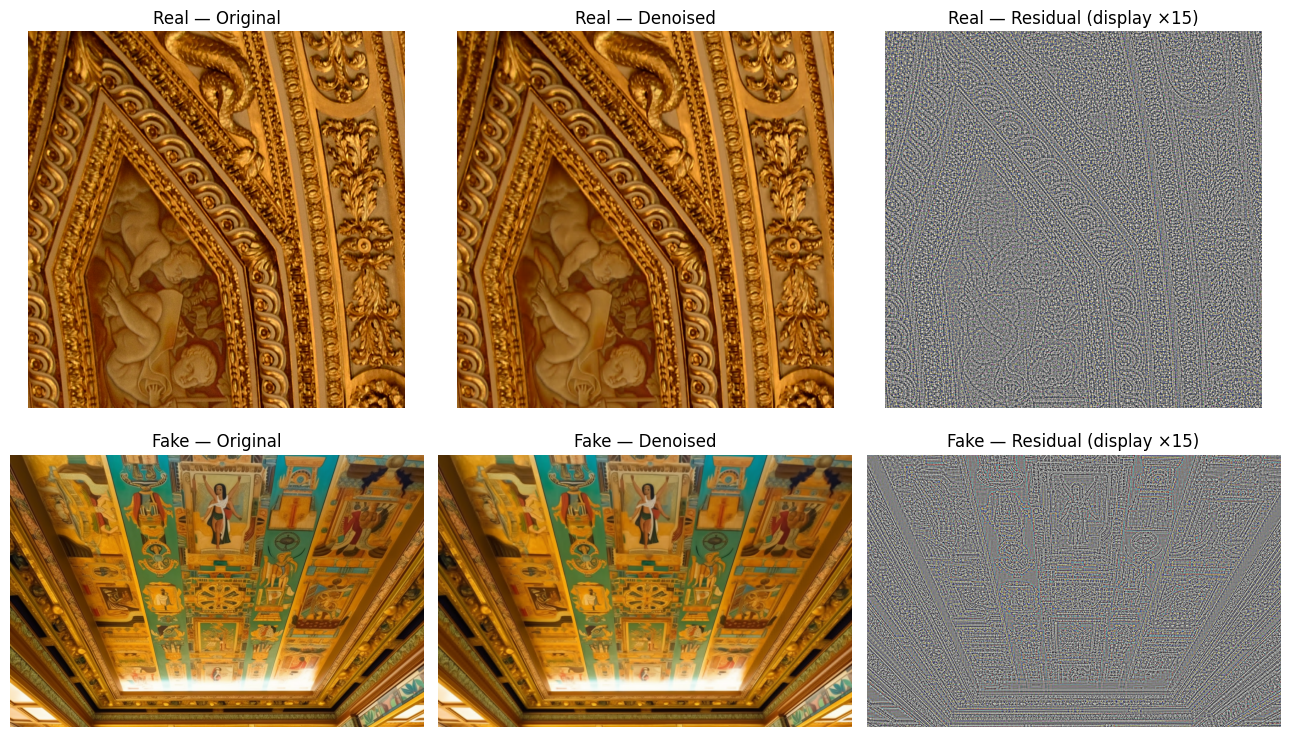

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(13, 8))

for row, (name, path) in enumerate([("Real", real_files[0]), ("Fake", fake_files[0])]):
    image = load_rgb(path)
    denoised, residual, sigmas = extract_noise(image)

    axes[row, 0].imshow(image)
    axes[row, 0].set_title(f"{name} — Original")

    axes[row, 1].imshow(np.clip(denoised, 0, 1))
    axes[row, 1].set_title(f"{name} — Denoised")

    axes[row, 2].imshow(np.clip(0.5 + 15 * residual, 0, 1))
    axes[row, 2].set_title(f"{name} — Residual (display ×15)")

    for ax in axes[row]:
        ax.axis("off")

    print(f"{name}: wavelet sigma (R,G,B) = {np.round(sigmas, 6)}")

plt.tight_layout()
plt.show()

## 5 — Une variance de résidu **par image**

Pour une image, on calcule les variances spatiales du résidu sur les trois canaux :

\[
v_R=\mathrm{Var}(\hat N_R),\quad v_G=\mathrm{Var}(\hat N_G),\quad v_B=\mathrm{Var}(\hat N_B),
\qquad v_{\mathrm{image}}=\frac{v_R+v_G+v_B}{3}.
\]

Chaque image contribue **une seule mesure** à la comparaison statistique. On ne traite pas les millions de pixels ou les paires d'images comme des observations indépendantes.

In [11]:
variance_cache = {}

def get_variance(path):
    if path not in variance_cache:
        image = load_rgb(path)
        _, residual, _ = extract_noise(image)

        variances = np.var(residual, axis=(0, 1))

        if not np.all(np.isfinite(variances)):
            raise ValueError(f"Non-finite residual variance in {path}: {variances}")

        variance_cache[path] = variances

    return variance_cache[path]


def compute_all_variances(paths, label):
    values = []

    for i, path in enumerate(paths, start=1):
        values.append(get_variance(path))

        if i % 10 == 0 or i == len(paths):
            print(f"{label}: {i}/{len(paths)} images")

    return np.array(values)


var_rgb_real = compute_all_variances(real_files, "Real")
var_rgb_fake = compute_all_variances(fake_files, "Fake")

real_values = var_rgb_real.mean(axis=1)
fake_values = var_rgb_fake.mean(axis=1)

assert np.isfinite(real_values).all() and np.isfinite(fake_values).all()

print("\nShape real:", var_rgb_real.shape)
print("Shape fake:", var_rgb_fake.shape)
print("Real median:", np.median(real_values))
print("Fake median:", np.median(fake_values))

Real: 10/50 images
Real: 20/50 images
Real: 30/50 images
Real: 40/50 images
Real: 50/50 images
Fake: 10/50 images
Fake: 20/50 images
Fake: 30/50 images
Fake: 40/50 images
Fake: 50/50 images

Shape real: (50, 3)
Shape fake: (50, 3)
Real median: 5.2057765109485445e-05
Fake median: 0.00019883897019166378


## 6 — Comparer les distributions (Real vs Fake)

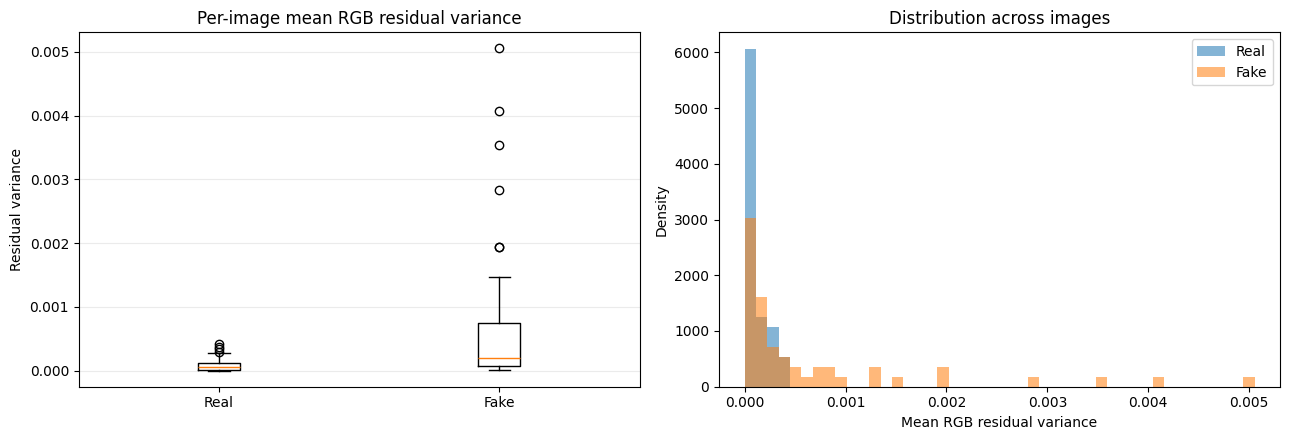

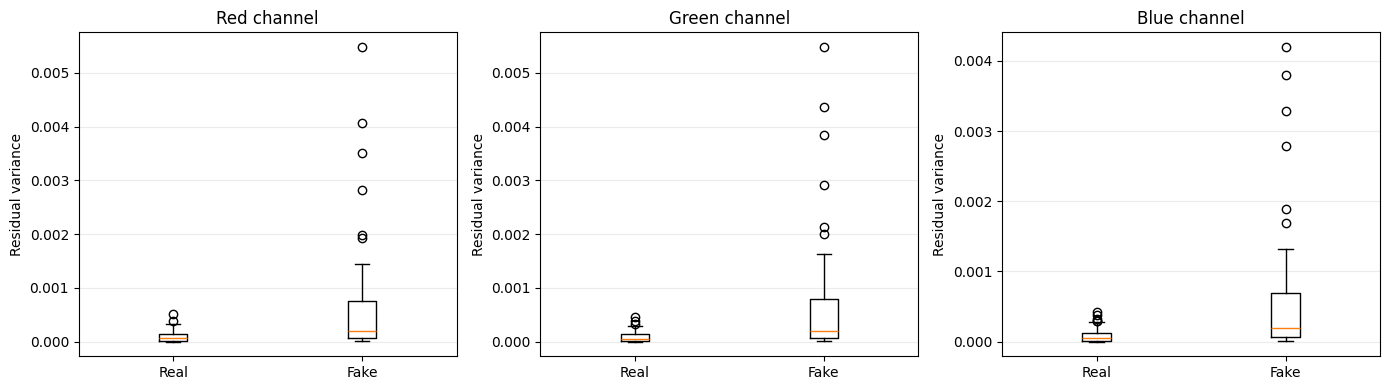

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].boxplot([real_values, fake_values])
axes[0].set_xticks([1, 2])
axes[0].set_xticklabels(["Real", "Fake"])
axes[0].set_title("Per-image mean RGB residual variance")
axes[0].set_ylabel("Residual variance")
axes[0].grid(axis="y", alpha=0.25)

bins = np.histogram_bin_edges(np.r_[real_values, fake_values], bins="auto")

axes[1].hist(real_values, bins=bins, density=True, alpha=0.55, label="Real")
axes[1].hist(fake_values, bins=bins, density=True, alpha=0.55, label="Fake")
axes[1].set_title("Distribution across images")
axes[1].set_xlabel("Mean RGB residual variance")
axes[1].set_ylabel("Density")
axes[1].legend()

plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

for c, (ax, name) in enumerate(zip(axes, ["Red", "Green", "Blue"])):
    ax.boxplot([var_rgb_real[:, c], var_rgb_fake[:, c]])
    ax.set_xticks([1, 2])
    ax.set_xticklabels(["Real", "Fake"])
    ax.set_title(f"{name} channel")
    ax.set_ylabel("Residual variance")
    ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

## 7 — Test de permutation et intervalle de confiance

**Hypothèse nulle \(H_0\) :** les valeurs de variance résiduelle des deux classes suivent la même distribution (leurs étiquettes sont échangeables). **Statistique testée :** différence des médianes \(\mathrm{med}(F)-\mathrm{med}(R)\).

On mélange aléatoirement les étiquettes réelles / fausses, en gardant le nombre d'images dans chaque groupe. La **p-value bilatérale** compare la différence observée à celles obtenues après permutation. Aucun modèle gaussien des variances n'est requis. Pour estimer l'incertitude sur l'effet, on calcule également un intervalle bootstrap à 95 % de la différence des médianes.

Observed median difference (Fake - Real): 0.00014678121
Two-sided permutation p-value: 0.00240
Bootstrap 95% CI: [4.308745e-05, 0.00036167772]


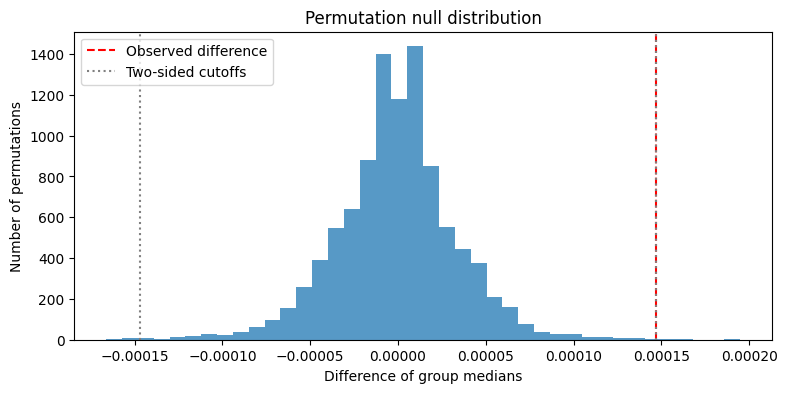

In [13]:
observed = np.median(fake_values) - np.median(real_values)
all_values = np.r_[real_values, fake_values]
n_real = len(real_values)

permuted = np.empty(N_PERMUTATIONS)

for b in range(N_PERMUTATIONS):
    shuffled = rng.permutation(all_values)
    permuted[b] = np.median(shuffled[n_real:]) - np.median(shuffled[:n_real])

p_value = (np.count_nonzero(np.abs(permuted) >= abs(observed)) + 1) / (N_PERMUTATIONS + 1)

boot_differences = np.empty(N_BOOTSTRAP)

for b in range(N_BOOTSTRAP):
    sampled_real = rng.choice(real_values, size=len(real_values), replace=True)
    sampled_fake = rng.choice(fake_values, size=len(fake_values), replace=True)
    boot_differences[b] = np.median(sampled_fake) - np.median(sampled_real)

ci_low, ci_high = np.quantile(boot_differences, [0.025, 0.975])

print(f"Observed median difference (Fake - Real): {observed:.8g}")
print(f"Two-sided permutation p-value: {p_value:.5f}")
print(f"Bootstrap 95% CI: [{ci_low:.8g}, {ci_high:.8g}]")

plt.figure(figsize=(9, 4))
plt.hist(permuted, bins=40, alpha=0.75)
plt.axvline(observed, color="red", linestyle="--", label="Observed difference")
plt.axvline(-abs(observed), color="gray", linestyle=":", label="Two-sided cutoffs")
plt.axvline(abs(observed), color="gray", linestyle=":")
plt.title("Permutation null distribution")
plt.xlabel("Difference of group medians")
plt.ylabel("Number of permutations")
plt.legend()
plt.show()

## 8 — ROC-AUC : capacité de discrimination

On utilise simplement la **variance par image comme score**, sans entraîner de modèle. Ici, on évalue une direction fixée à l'avance : **variance plus grande ⇒ image probablement générée**. Si ce choix était dicté par les mêmes données, le résultat est exploratoire ; il faudra le valider sur un autre ensemble d'images.

L'AUC correspond à la probabilité qu'une image fake ait un score supérieur à celui d'une image real (une égalité compte pour 0.5). Une AUC de 0.5 correspond à une absence de discrimination dans ce sens ; une AUC proche de 0 indique que le score classe dans l'autre sens.

ROC-AUC (higher variance means Fake): 0.7620
ROC-AUC if direction were reversed: 0.2380 (descriptive only)


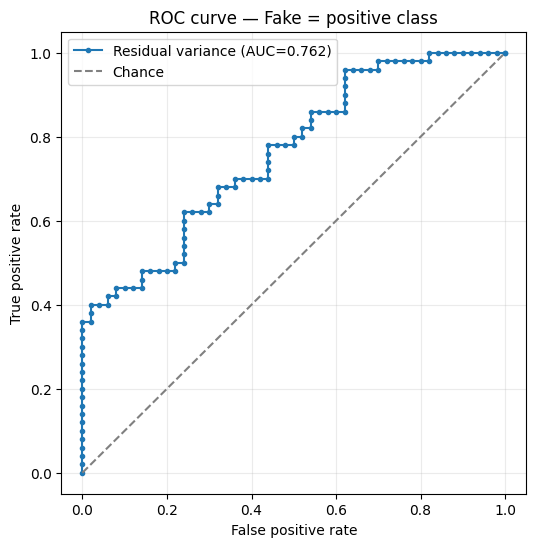

In [14]:
pairwise = fake_values[:, None] - real_values[None, :]
auc = np.mean(pairwise > 0) + 0.5 * np.mean(pairwise == 0)

thresholds = np.r_[np.inf, np.sort(np.unique(np.r_[real_values, fake_values]))[::-1], -np.inf]

fpr = np.array([(real_values >= t).mean() for t in thresholds])
tpr = np.array([(fake_values >= t).mean() for t in thresholds])

print(f"ROC-AUC (higher variance means Fake): {auc:.4f}")
print(f"ROC-AUC if direction were reversed: {1-auc:.4f} (descriptive only)")

plt.figure(figsize=(6, 6))
plt.plot(fpr, tpr, marker=".", label=f"Residual variance (AUC={auc:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Chance")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("ROC curve — Fake = positive class")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

## 9 — Résumé numérique et interprétation

- Une p-value faible signifie que la différence observée est peu compatible avec l'échangeabilité des groupes, **pas** que chaque image est reconnaissable.
- Une AUC proche de 0.5 indique que la variance seule distingue mal les classes, même si les médianes diffèrent.
- Le résultat dépend du contenu, de la résolution, de la compression, du traitement de l'appareil et de l'algorithme de débruitage. Idéalement, comparer des jeux d'images équilibrés et aux traitements comparables, puis confirmer sur un jeu **indépendant**.
- Les trois canaux RGB peuvent contenir des informations différentes ; ne pas les traiter comme trois images indépendantes.

In [ ]:
print("=== SUMMARY ===")
print(f"Number of real images: {len(real_values)}")
print(f"Number of fake images: {len(fake_values)}")
print(f"Real mean / median variance: {np.mean(real_values):.8g} / {np.median(real_values):.8g}")
print(f"Fake mean / median variance: {np.mean(fake_values):.8g} / {np.median(fake_values):.8g}")
print(f"Difference in medians (Fake - Real): {observed:.8g}")
print(f"95% bootstrap CI: [{ci_low:.8g}, {ci_high:.8g}]")
print(f"Permutation p-value: {p_value:.5f}")
print(f"ROC-AUC (Fake higher): {auc:.4f}")

if p_value < 0.05:
    print("At the 5% level: evidence against identical score distributions.")
else:
    print("At the 5% level: no significant evidence against identical score distributions.")

print("These are exploratory results, not proof that an image was generated by AI.")

## 10 — Complément facultatif : RR / RF / FF

Cette section reprend ton idée initiale : on compare la **différence absolue des variances** de deux images, moyennée sur RGB. Les groupes RR et FF donnent une mesure de la dispersion **à l'intérieur** des classes ; RF donne la dispersion **entre** classes. Les paires réutilisent certaines images : **ne pas appliquer de test statistique en les considérant comme des observations indépendantes**.

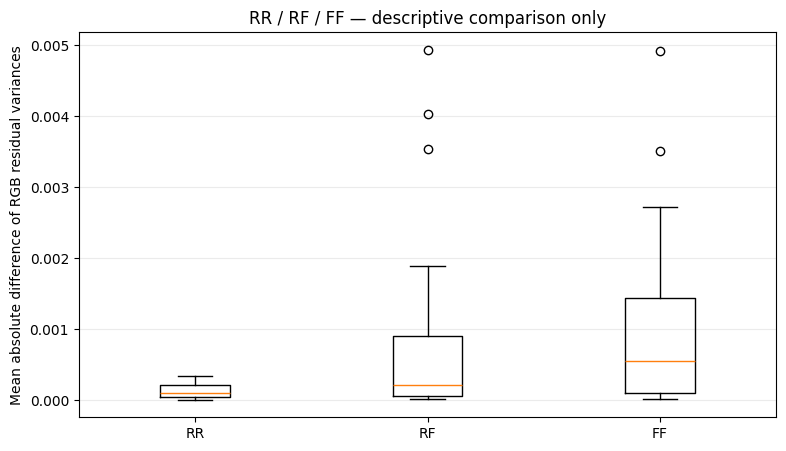

RR: 30 pairs, median distance = 0.00010261252
RF: 30 pairs, median distance = 0.00021424119
FF: 30 pairs, median distance = 0.00055116817


In [9]:
a = 30
pair_rng = np.random.default_rng(SEED)

rr_candidates = list(combinations(range(len(real_files)), 2))
rf_candidates = list(product(range(len(real_files)), range(len(fake_files))))
ff_candidates = list(combinations(range(len(fake_files)), 2))

def sample_pairs(candidates, count):
    n = min(count, len(candidates))
    selected = pair_rng.choice(len(candidates), size=n, replace=False)
    return [candidates[i] for i in selected]

RR_pairs = sample_pairs(rr_candidates, a)
RF_pairs = sample_pairs(rf_candidates, a)
FF_pairs = sample_pairs(ff_candidates, a)

RR_scores = np.array([np.mean(np.abs(var_rgb_real[i] - var_rgb_real[j])) for i, j in RR_pairs])
RF_scores = np.array([np.mean(np.abs(var_rgb_real[i] - var_rgb_fake[j])) for i, j in RF_pairs])
FF_scores = np.array([np.mean(np.abs(var_rgb_fake[i] - var_rgb_fake[j])) for i, j in FF_pairs])

plt.figure(figsize=(9, 5))
plt.boxplot([RR_scores, RF_scores, FF_scores])
plt.xticks([1, 2, 3], ["RR", "RF", "FF"])
plt.ylabel("Mean absolute difference of RGB residual variances")
plt.title("RR / RF / FF — descriptive comparison only")
plt.grid(axis="y", alpha=0.25)
plt.show()

for name, scores in zip(["RR", "RF", "FF"], [RR_scores, RF_scores, FF_scores]):
    print(f"{name}: {len(scores)} pairs, median distance = {np.median(scores):.8g}")

### Bilan de la démarche

Ce notebook suit le pipeline : **image → ondelettes → résidu RGB → variance par image → test de permutation → ROC-AUC**. La comparaison RR/RF/FF est complémentaire, et non le test principal. Une différence de résidus peut venir de la génération, mais aussi des caractéristiques du dataset. Un résultat convaincant exige une validation sur de nouvelles images et des conditions de traitement comparables.

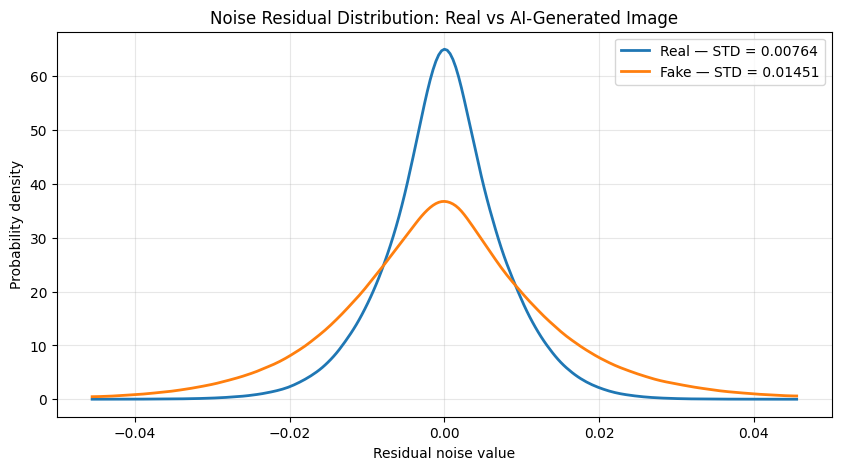

Real STD: 0.007635
Fake STD: 0.014513


In [11]:
from scipy.ndimage import gaussian_filter1d

rng = np.random.default_rng()

real_path = rng.choice(real_files)

fake_path = rng.choice(fake_files)

noise_real = extract_noise(load_rgb(real_path))[1]

noise_fake = extract_noise(load_rgb(fake_path))[1]

std_real = np.sqrt(np.mean(np.var(noise_real, axis=(0, 1))))

std_fake = np.sqrt(np.mean(np.var(noise_fake, axis=(0, 1))))

real_data = noise_real.flatten()

fake_data = noise_fake.flatten()

limit = np.quantile(np.abs(np.concatenate([real_data, fake_data])), 0.995)

bins = np.linspace(-limit, limit, 250)

hist_real, edges = np.histogram(real_data, bins=bins, density=True)

hist_fake, _ = np.histogram(fake_data, bins=bins, density=True)

centers = (edges[:-1] + edges[1:]) / 2

plt.figure(figsize=(10, 5))

plt.plot(centers, gaussian_filter1d(hist_real, 2), label=f"Real — STD = {std_real:.5f}", linewidth=2)

plt.plot(centers, gaussian_filter1d(hist_fake, 2), label=f"Fake — STD = {std_fake:.5f}", linewidth=2)

plt.xlabel("Residual noise value")

plt.ylabel("Probability density")

plt.title("Noise Residual Distribution: Real vs AI-Generated Image")

plt.legend()

plt.grid(alpha=0.3)

plt.show()

print(f"Real STD: {std_real:.6f}")

print(f"Fake STD: {std_fake:.6f}")

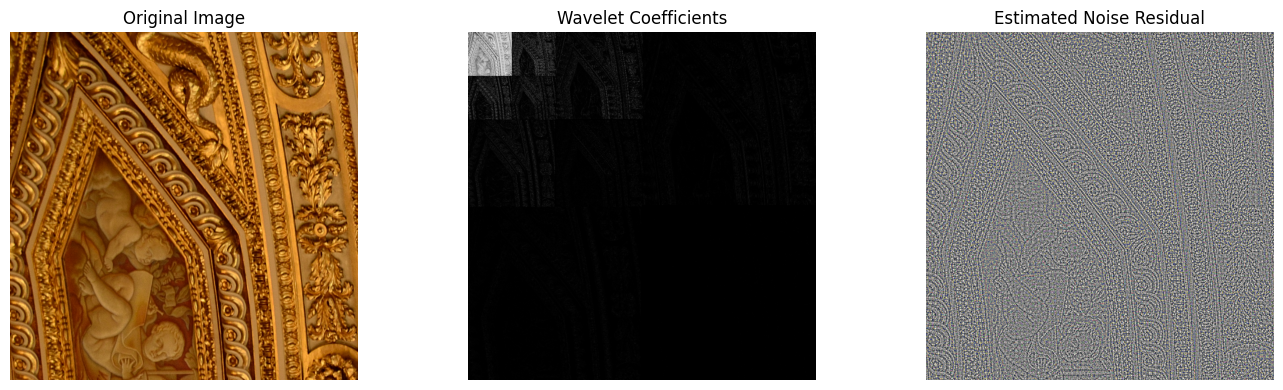

In [12]:
import pywt

import matplotlib.pyplot as plt

import numpy as np

image = load_rgb(real_files[0])

gray = np.mean(image, axis=2)

coeffs = pywt.wavedec2(gray, "db2", level=3)

wavelet_array, _ = pywt.coeffs_to_array(coeffs)

denoised, noise, _ = extract_noise(image)

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

axes[0].imshow(image)

axes[0].set_title("Original Image")

axes[1].imshow(np.log1p(np.abs(wavelet_array)), cmap="gray")

axes[1].set_title("Wavelet Coefficients")

axes[2].imshow(np.clip(0.5 + 15 * noise, 0, 1))

axes[2].set_title("Estimated Noise Residual")

for ax in axes:

    ax.axis("off")

plt.tight_layout()

plt.savefig("wavelet_visual.png", dpi=300, bbox_inches="tight")

plt.show()